<a href="https://colab.research.google.com/github/Gowsick232/gowsick-dl/blob/main/Copy_of_cat_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from google.colab import files
print("Please select and upload your dataset file (.csv or .csv.gz) from your local drive:")
uploaded = files.upload()
uploaded_file_name = list(uploaded.keys())[0]
print(f"Successfully uploaded: {uploaded_file_name}")
df = pd.read_csv(uploaded_file_name)
display(df.head())

Please select and upload your dataset file (.csv or .csv.gz) from your local drive:


Saving traffic-volume-prediction.csv.ipynb to traffic-volume-prediction.csv.ipynb
Successfully uploaded: traffic-volume-prediction.csv.ipynb


,"{""cells"":[{""cell_type"":""markdown""","id:""a5fb0cb3""","metadata:{""papermill"":{""duration"":0.011786","end_time:""2023-07-31T12:08:58.747689""",exception:false,"start_time:""2023-07-31T12:08:58.735903""","status:""completed""}",tags:[]},"source:[""# Introduction\n""",\n,...,"version:""2.4.0""}","kaggle:{""accelerator"":""none""","dataSources:[{""sourceType"":""datasetVersion""",sourceId:6203292}],isInternetEnabled:true,"language:""python"".1","sourceType:""notebook""",isGpuEnabled:false}},nbformat:4,nbformat_minor:5}


In [ ]:
import os
import pandas as pd
from google.colab import files

# Fallback uploading directly to Colab storage if Drive mount fails
print("Please select and upload your dataset file (.csv or .csv.gz) from your local drive:")
uploaded = files.upload()

if uploaded:
    local_file_name = list(uploaded.keys())[0]
    print(f"\nSuccessfully uploaded: {local_file_name}")

    # Load the dataset into pandas
    df = pd.read_csv(local_file_name)
    display(df.head())
else:
    print("No file was uploaded.")

Found valid preprocessed dataset in session!


,temp,rain_1h,snow_1h,clouds_all,traffic_volume,is_holiday,hour_sin,hour_cos,weekday_sin,weekday_cos
date_time,,,,,,,,,,
2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545.0,0,7.071068e-01,-0.707107,0.781831,0.62349
2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516.0,0,5.000000e-01,-0.866025,0.781831,0.62349
2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767.0,0,2.588190e-01,-0.965926,0.781831,0.62349
2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026.0,0,1.224647e-16,-1.000000,0.781831,0.62349
2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918.0,0,-2.588190e-01,-0.965926,0.781831,0.62349


Original dataset shape: (48204, 9)
  holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0     NaN  288.28      0.0      0.0          40       Clouds   
1     NaN  289.36      0.0      0.0          75       Clouds   
2     NaN  289.58      0.0      0.0          90       Clouds   
3     NaN  290.13      0.0      0.0          90       Clouds   
4     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description            date_time  traffic_volume  
0    scattered clouds  2012-10-02 09:00:00            5545  
1       broken clouds  2012-10-02 10:00:00            4516  
2     overcast clouds  2012-10-02 11:00:00            4767  
3     overcast clouds  2012-10-02 12:00:00            5026  
4       broken clouds  2012-10-02 13:00:00            4918  

Processed continuous hourly segment:
Number of records: 5000
Start: 2012-10-02 09:00:00
End: 2013-04-28 16:00:00

Sequence shapes:
X_train: (3476, 24, 10)
X_val:   (750, 24, 10)
X_test:  (750, 24, 10)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        19,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,161 (125.63 KB)

 Trainable params: 32,161 (125.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - loss: 0.0593 - mae: 0.1901 - val_loss: 0.0270 - val_mae: 0.1200
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0283 - mae: 0.1249 - val_loss: 0.0178 - val_mae: 0.0956
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0234 - mae: 0.1112 - val_loss: 0.0149 - val_mae: 0.0868
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0206 - mae: 0.1036 - val_loss: 0.0117 - val_mae: 0.0766
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0179 - mae: 0.0970 - val_loss: 0.0097 - val_mae: 0.0685
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0150 - mae: 0.0887 - val_loss: 0.0079 - val_mae: 0.0619
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0144 - mae: 0.0860 - val_loss: 0.0076 - val_mae: 0.0619
Epoch 8/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - loss: 0.0129 - mae: 0.0819 - val_loss: 0.0071 - val_mae: 0.0592
Epoch 9/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.012

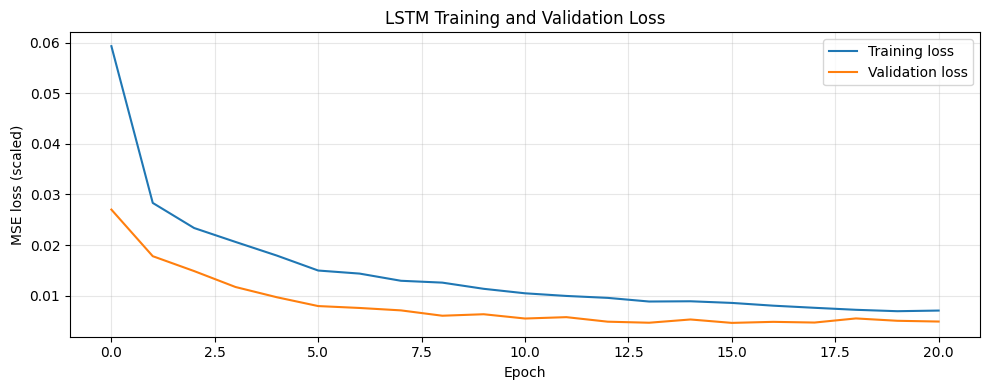

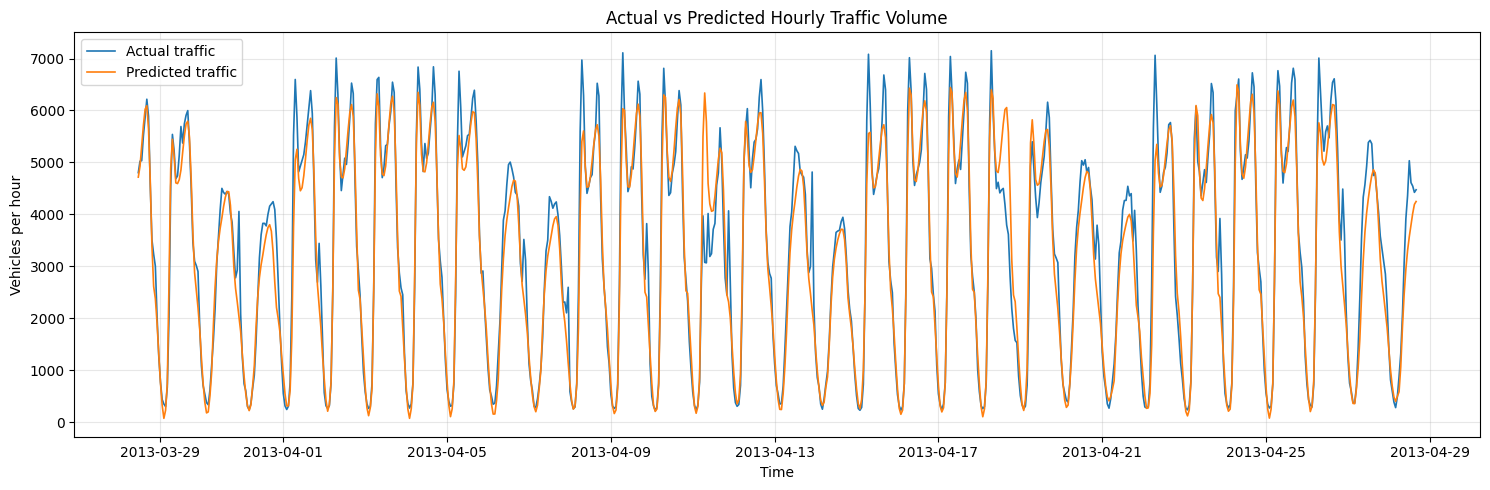

In [ ]:
!pip install ucimlrepo -q
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
np.random.seed(42)
tf.random.set_seed(42)
print("Downloading the UCI traffic dataset...")
dataset = fetch_ucirepo(id=492)
df = dataset.data.features.copy()
df["traffic_volume"] = dataset.data.targets["traffic_volume"].values
print("Original dataset shape:", df.shape)
print(df.head())
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")
df = df.dropna(subset=["date_time", "traffic_volume"])
df = df.sort_values("date_time")
df = df.drop_duplicates(subset=["date_time"], keep="last")
numeric_cols = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df.loc[df["temp"] <= 0, "temp"] = np.nan
df = df.set_index("date_time")
if "holiday" in df.columns:
    df["is_holiday"] = (
        df["holiday"].notna()
        & ~df["holiday"].astype(str).str.lower().isin(["none", "nan", ""])
    ).astype(int)
else:
    df["is_holiday"] = 0
hourly = df.resample("H").mean(numeric_only=True)
hourly["is_holiday"] = df["is_holiday"].resample("H").max().fillna(0).astype(int)
features = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all", "is_holiday"]
hourly[features] = hourly[features].interpolate(method="linear").ffill().bfill()
hourly = hourly.iloc[:5000]
print("\nProcessed continuous hourly segment:")
print("Number of records:", len(hourly))
print("Start:", hourly.index.min())
print("End:", hourly.index.max())
hourly["hour_sin"] = np.sin(2 * np.pi * hourly.index.hour / 24)
hourly["hour_cos"] = np.cos(2 * np.pi * hourly.index.hour / 24)
hourly["weekday_sin"] = np.sin(2 * np.pi * hourly.index.dayofweek / 7)
hourly["weekday_cos"] = np.cos(2 * np.pi * hourly.index.dayofweek / 7)
features += [
    "hour_sin", "hour_cos",
    "weekday_sin", "weekday_cos"
]
data = hourly[features].astype("float32")
n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()
x_scaler.fit(data.iloc[:train_end][features])
y_scaler.fit(data.iloc[:train_end][["traffic_volume"]])
X_scaled = x_scaler.transform(data[features])
y_scaled = y_scaler.transform(data[["traffic_volume"]]).flatten()
LOOKBACK = 24
HORIZON = 1
def make_windows(X, y, lookback=24, horizon=1):
    X_seq, y_seq, target_positions = [], [], []
    for end in range(lookback, len(X) - horizon + 1):
        target_pos = end + horizon - 1
        X_seq.append(X[end - lookback:end])
        y_seq.append(y[target_pos])
        target_positions.append(target_pos)
    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(target_positions)
    )

X_all, y_all, target_positions = make_windows(
    X_scaled, y_scaled, LOOKBACK, HORIZON
)
train_mask = target_positions < train_end
val_mask = (target_positions >= train_end) & (target_positions < val_end)
test_mask = target_positions >= val_end
X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
test_positions = target_positions[test_mask]
test_timestamps = data.index[test_positions]
print("\nSequence shapes:")
print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(LOOKBACK, len(features))),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(HORIZON)
])
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)
model.summary()
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)
pred_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)
y_pred = y_scaler.inverse_transform(pred_scaled).flatten()
y_actual = y_scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred = np.maximum(y_pred, 0)
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
print("\n========== TEST RESULTS ==========")
print(f"MAE :  {mae:.2f} vehicles/hour")
print(f"RMSE:  {rmse:.2f} vehicles/hour")
results = pd.DataFrame({
    "timestamp": test_timestamps,
    "actual_traffic": y_actual,
    "predicted_traffic": y_pred
})
results.to_csv("traffic_forecast_results.csv", index=False)
print("\nSaved traffic_forecast_results.csv")
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (scaled)")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.figure(figsize=(15, 5))
plt.plot(test_timestamps, y_actual, label="Actual traffic", linewidth=1.2)
plt.plot(test_timestamps, y_pred, label="Predicted traffic", linewidth=1.2)
plt.xlabel("Time")
plt.ylabel("Vehicles per hour")
plt.title("Actual vs Predicted Hourly Traffic Volume")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
